In [1]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")                    # sobe para a raiz do projeto
sys.path.insert(0, str(Path.cwd()))   # para o Python achar a pasta mercado/
print("trabalhando em:", Path.cwd())

import pandas as pd
from mercado.base_precos import carregar_base, carregar_catalogo, limpar

obs = limpar(carregar_base(), carregar_catalogo())
obs.shape

trabalhando em: .


(15739, 16)

In [2]:
%load_ext autoreload
%autoreload 2
from mercado.estatisticas import referencia_mercado

In [3]:
obs.dtypes

data_pesquisa                object
id_empresa                   object
rede                         object
endereco_completo            object
codigo_categoria             object
id_produto                   object
descricao                    object
preco_regular               float64
preco_atacado                object
preco_atacado_qtd            object
preco_promocao               object
preco_fidelidade             object
__mes                        object
__arq                        object
data                 datetime64[ns]
grupo                        object
dtype: object

In [4]:
obs.head(3)

,data_pesquisa,id_empresa,rede,endereco_completo,codigo_categoria,id_produto,descricao,preco_regular,preco_atacado,preco_atacado_qtd,preco_promocao,preco_fidelidade,__mes,__arq,data,grupo
0,2024-01-02,42,Atacadão,"Avenida Ver Toaldo Túlio, 2780 - Curitiba/PR",1,7896016700149,CAFE VÁCUO -ALVORADA -500 GR,13.99,0.00,0,0.00,0.00,2024-01,2024-01-03_Clique_Economia_-_Cotacoes_-_Base_d...,2024-01-02,Café
1,2024-01-03,26,Jacomar,Rua Desembargador Antônio de Paula - 2765 - Bo...,1,7896016700149,CAFE VÁCUO -ALVORADA -500 GR,11.98,0.00,0,0.00,0.00,2024-01,2024-01-03_Clique_Economia_-_Cotacoes_-_Base_d...,2024-01-03,Café
2,2024-01-03,26,Jacomar,Rua Desembargador Antônio de Paula - 2765 - Bo...,6,7891528029498,CREME DENTAL TRIPLA LIMPEZA COMPLETA -SORRISO ...,2.79,0.00,0,0.00,0.00,2024-01,2024-01-03_Clique_Economia_-_Cotacoes_-_Base_d...,2024-01-03,Creme dental


In [5]:
pd.Series({
    "meses": obs["__mes"].nunique(),
    "primeiro": obs["__mes"].min(),
    "ultimo": obs["__mes"].max(),
    "produtos": obs["id_produto"].nunique(),
    "redes": obs["rede"].nunique(),
    "lojas": obs["endereco_completo"].nunique(),
})

meses            33
primeiro    2024-01
ultimo      2026-10
produtos         50
redes            52
lojas           108
dtype: object

In [6]:
id_produto = "7894900027013"
mes_final = "2026-10"

rodadas = sorted(obs["__mes"].unique())
fim = rodadas.index(mes_final)
janela = rodadas[max(0, fim - 2): fim + 1]
janela

['2026-08', '2026-09', '2026-10']

In [7]:
sel = obs[(obs["id_produto"] == id_produto) & (obs["__mes"].isin(janela))]
len(sel), sel["rede"].nunique(), sel["endereco_completo"].nunique()

(28, 15, 28)

In [8]:
por_rede = sel.groupby("rede")["preco_regular"].median().sort_values()
por_rede

rede
Super Muffato     10.980
Condor            10.985
Carrefour         11.290
Jacomar           11.480
Stall             11.480
REDE MASTER       11.490
Assaí             11.640
Palmeira          11.850
Araucária         11.990
Atacadão          11.990
Telêmaco          11.990
Triunfo           12.480
Gabão             12.950
Super Curitiba    12.980
Festval           12.990
Name: preco_regular, dtype: float64

In [9]:
pd.Series({
    "mediana": por_rede.median(),
    "p25": por_rede.quantile(0.25),
    "p75": por_rede.quantile(0.75),
    "n_obs": len(sel),
    "n_lojas": sel["endereco_completo"].nunique(),
    "n_redes": len(por_rede),
    "ultima_obs": sel["data"].max(),
})

mediana                     11.85
p25                         11.48
p75                        12.235
n_obs                          28
n_lojas                        28
n_redes                        15
ultima_obs    2026-10-01 00:00:00
dtype: object

Valores em reais arredondados com Decimal, ROUND_HALF_UP meio centavo para cima

In [10]:
from decimal import Decimal, ROUND_HALF_UP

def reais(valor):
    """Arredonda dinheiro em 2 casas, meio centavo para cima (12,235 -> 12,24)."""
    return float(Decimal(str(valor)).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))

In [11]:
def referencia_mercado(obs, id_produto, mes_final, n_rodadas=3, camada="observado", min_redes=3):
    """Referência de mercado de um SKU numa janela de rodadas que termina em mes_final.
    Mediana por rede primeiro, depois entre redes: cada rede vale um voto."""

    base = obs
    if "camada" in obs.columns:
        base = obs[obs["camada"] == camada]

    rodadas = sorted(obs["__mes"].unique())
    if mes_final not in rodadas:
        raise ValueError(f"rodada {mes_final} não existe na base")
    fim = rodadas.index(mes_final)
    janela = rodadas[max(0, fim - n_rodadas + 1): fim + 1]

    sel = base[(base["id_produto"] == id_produto) & (base["__mes"].isin(janela))]
    if sel.empty:
        raise LookupError(f"sem observações de {id_produto} em {janela}")

    por_rede = sel.groupby("rede")["preco_regular"].median()

    return {
        "id_produto": id_produto,
        "janela": janela,
        "camada": camada,
        "mediana": reais(por_rede.median()),
        "p25": reais(por_rede.quantile(0.25)),
        "p75": reais(por_rede.quantile(0.75)),
        "n_obs": len(sel),
        "n_lojas": sel["endereco_completo"].nunique(),
        "n_redes": len(por_rede),
        "ultima_obs": sel["data"].max().strftime("%Y-%m-%d"),
        "cobertura_ok": len(por_rede) >= min_redes,
    }

referencia_mercado(obs, "7894900027013", "2026-10")

{'id_produto': '7894900027013',
 'janela': ['2026-08', '2026-09', '2026-10'],
 'camada': 'observado',
 'mediana': 11.85,
 'p25': 11.48,
 'p75': 12.24,
 'n_obs': 28,
 'n_lojas': 28,
 'n_redes': 15,
 'ultima_obs': '2026-10-01',
 'cobertura_ok': True}

In [12]:
r = referencia_mercado(obs, "7894900027013", "2026-10")

assert r["janela"] == ["2026-08", "2026-09", "2026-10"]
assert r["mediana"] == 11.85
assert (r["p25"], r["p75"]) == (11.48, 12.24)
assert (r["n_obs"], r["n_lojas"], r["n_redes"]) == (28, 28, 15)
assert r["cobertura_ok"] is True
print("ok")

ok


In [13]:
for pid in ["7894900027013", "7892840800246", "7891991001342", "7896188403077"]:
    r = referencia_mercado(obs, pid, "2026-10")
    print(pid, r["mediana"], r["p25"], r["p75"], r["n_redes"], r["cobertura_ok"])

7894900027013 11.85 11.48 12.24 15 True
7892840800246 8.99 8.99 9.52 12 True
7891991001342 9.82 9.54 10.17 15 True
7896188403077 5.6 5.14 5.99 15 True


In [14]:
from mercado.estatisticas import historico_referencia

hist = historico_referencia(obs, "7894900027013")
hist

,mediana,p25,p75,n_lojas,n_redes,cobertura_ok
mes,,,,,,
2024-01,NaN,NaN,NaN,0,0,False
2024-02,NaN,NaN,NaN,0,0,False
2024-03,NaN,NaN,NaN,0,0,False
2024-04,NaN,NaN,NaN,0,0,False
2024-06,NaN,NaN,NaN,0,0,False
2024-07,NaN,NaN,NaN,0,0,False
2024-08,NaN,NaN,NaN,0,0,False
2024-09,NaN,NaN,NaN,0,0,False
2024-10,10.29,9.69,10.49,24,15,True


In [15]:
   hist = hist.astype({"mediana": float, "p25": float, "p75": float})

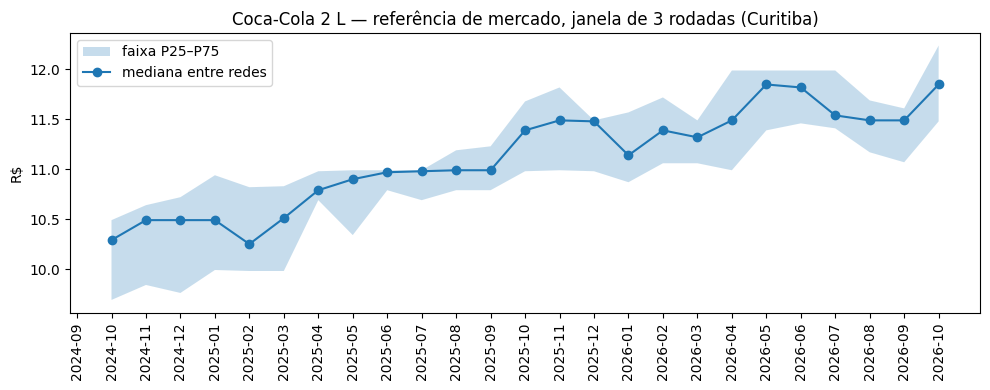

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(hist.index, hist["p25"], hist["p75"], alpha=0.25, label="faixa P25–P75")
ax.plot(hist.index, hist["mediana"], marker="o", label="mediana entre redes")
ax.set_title("Coca-Cola 2 L — referência de mercado, janela de 3 rodadas (Curitiba)")
ax.set_ylabel("R$")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.tight_layout()

In [17]:
from mercado.estatisticas import similares

similares(obs, "7894900027013", "2026-10")

,descricao,mediana,p25,p75,n_redes,cobertura_ok,indice,escolhido
id_produto,,,,,,,,
7894900027013,REFRIGERANTE -COCA COLA -2 LITRO,11.85,11.48,12.24,15,True,100,True
7891991001342,REFRIGERANTE GUARANÁ -ANTÁRTICA -2 LITRO,9.82,9.54,10.17,15,True,83,False
7892840800246,REFRIGERANTE COCA COLA -PEPSI -2 LITRO,8.99,8.99,9.52,12,True,76,False
7896188403077,REFRIGERANTE GUARANÁ -CINI -2 LITRO,5.60,5.14,5.99,15,True,47,False


In [18]:
s = similares(obs, "7894900027013", "2026-10")

assert s.loc["7894900027013", "indice"] == 100
assert s.loc["7892840800246", "indice"] == 76      # Pepsi
assert s.loc["7896188403077", "indice"] == 47
assert s["escolhido"].sum() == 1
print("ok")

ok


In [20]:
similares(obs, "7896038306039", "2026-10")   

,descricao,mediana,p25,p75,n_redes,cobertura_ok,indice,escolhido
id_produto,,,,,,,,
7893500020158,ARROZ POLIDO -TIO JOÃO -5 KG,38.74,33.99,39.90,13,True,167,False
7896290300011,ARROZ POLIDO -PRATO FINO -5 KG,31.39,28.80,32.90,13,True,135,False
7896290300332,ARROZ PARBOILIZADO -PRATO FINO -5 KG,27.99,26.99,30.29,12,True,121,False
7896038321032,ARROZ POLIDO -TIO URBANO -5 KG,24.99,24.13,26.67,14,True,108,False
7896267004102,ARROZ POLIDO -BURITI -5 KG,23.99,21.64,25.06,14,True,104,False
7896038306039,ARROZ PARBOILIZADO -URBANO -5 KG,23.17,21.53,24.34,10,True,100,True
7896267000135,ARROZ PARBOILIZADO -BURITI -5 KG,19.24,17.50,19.98,14,True,83,False


In [21]:
from mercado.estatisticas import historico_referencia

ids = obs["id_produto"].unique()
cob = pd.concat({pid: historico_referencia(obs, pid)["n_redes"] for pid in ids}, axis=1)

baixa = (cob < 3) & (cob > 0)       # tem preço, mas menos de 3 redes
print("SKU-meses com preço:", (cob > 0).sum().sum())
print("SKU-meses com cobertura baixa:", baixa.sum().sum())
baixa.sum().sort_values(ascending=False).head(10)

SKU-meses com preço: 1264
SKU-meses com cobertura baixa: 0


7896016700149    0
7896188403077    0
7891149200504    0
7898247780297    0
7896034610017    0
7896262500050    0
7898215157403    0
7891149010509    0
7891910008353    0
7891097018251    0
dtype: int64